# **King County Housing Sale: Data Exploration & Preprocessing**

## Import Packages, Libraries & Data

In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv('data/kc_house_data.csv')
print("First five rows:\n", df.head())
print("Dataframe dimensions:\n", df.shape)

First five rows:
            id             date     price  bedrooms  bathrooms  sqft_living  \
0  7129300520  20141013T000000  221900.0         3       1.00         1180   
1  6414100192  20141209T000000  538000.0         3       2.25         2570   
2  5631500400  20150225T000000  180000.0         2       1.00          770   
3  2487200875  20141209T000000  604000.0         4       3.00         1960   
4  1954400510  20150218T000000  510000.0         3       2.00         1680   

   sqft_lot  floors  waterfront  view  ...  grade  sqft_above  sqft_basement  \
0      5650     1.0           0     0  ...      7        1180              0   
1      7242     2.0           0     0  ...      7        2170            400   
2     10000     1.0           0     0  ...      6         770              0   
3      5000     1.0           0     0  ...      7        1050            910   
4      8080     1.0           0     0  ...      8        1680              0   

   yr_built  yr_renovated  zipco

## Exploratory Data Analysis (EDA)
- Here's a series of visualizations to describe the existing dataset

In [3]:
center_lat = df["lat"].mean()
center_lon = df["long"].mean()

fig = px.scatter_map(
    df,
    lat="lat",
    lon="long",
    hover_name="id",
    hover_data={"price": ":,.0f", "zipcode": True, "lat": False, "long": False},
    zoom=8.6,
    center={"lat": center_lat, "lon": center_lon},
    map_style="open-street-map",
    title="House locations in King County, WA",
    subtitle="showcasing the distribution of housing sales from 2014-15"
)

fig.update_traces(marker={"size": 5, "opacity": 0.45})
fig.show()


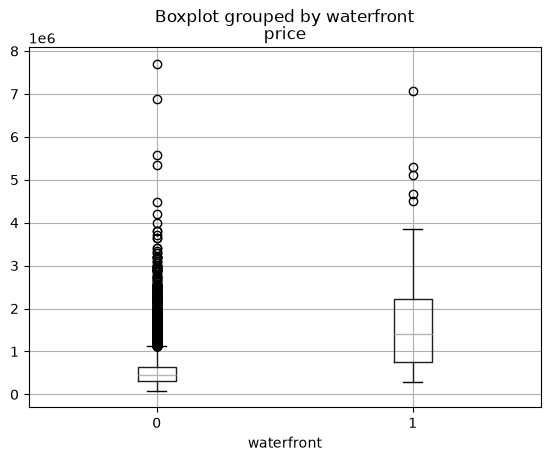

In [4]:
waterfront_boxplot =df.boxplot(column='price', by='waterfront')


In [5]:
df["decade"] = (df["yr_built"] // 10) * 10

decade_counts = (
    df["decade"]
    .value_counts()
    .sort_index()
    .rename("count")
    .reset_index()
)

fig_decade_counts = px.bar(
    decade_counts,
    x="decade",
    y="count",
    title="Distribution of Houses Built by Decade",
    labels={"decade": "Decade built", "count": "Number of houses"},
)
fig_decade_counts.update_xaxes(type="category")
fig_decade_counts.show()

decade_avg_price = (
    df.groupby("decade", as_index=False)["price"]
    .mean()
    .sort_values("decade")
)

fig_decade_price = px.bar(
    decade_avg_price,
    x="decade",
    y="price",
    title="Average Sale Price by Decade Built",
    labels={"decade": "Decade built", "price": "Average price (USD)"},
)
fig_decade_price.update_traces(hovertemplate="Decade: %{x}<br>Avg price: $%{y:,.0f}<extra></extra>")
fig_decade_price.update_xaxes(type="category")
fig_decade_price.show()

### Living Area vs. Price Distributions
- Heatmap of **average sale price** across **living area** (`sqft_living`) bins (and bedrooms for structure).
- **Histograms** of `price` on the original scale and on **log10** scale to inspect skew and the luxury tail (useful when deciding whether to model `log(price)`).


In [6]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

sqft_edges = list(range(0, 14_000, 500)) + [df["sqft_living"].max() + 1]
df_eda = df.assign(
    sqft_bin=pd.cut(df["sqft_living"], bins=sqft_edges, right=False),
    bedrooms_capped=df["bedrooms"].clip(upper=8),
)

avg_price_grid = df_eda.pivot_table(
    index="bedrooms_capped",
    columns="sqft_bin",
    values="price",
    aggfunc="mean",
    observed=True,
)

x_labels = avg_price_grid.columns.astype(str).tolist()
y_labels = avg_price_grid.index.astype(int).tolist()

fig_sqft_heatmap = px.imshow(
    avg_price_grid.to_numpy(),
    x=x_labels,
    y=y_labels,
    title="Average Sale Price by Living Area and Bedrooms",
    labels={
        "x": "Living Area Bins (sq ft)",
        "y": "Bedrooms (capped at 8)",
        "color": "Average Price (USD)",
    },
    aspect="auto",
    color_continuous_scale="Viridis",
)
fig_sqft_heatmap.show()

log_price = np.log10(df["price"])

fig_price_hist = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("Sale Price (USD)", "log10(Sale Price)"),
)

fig_price_hist.add_trace(
    go.Histogram(x=df["price"], name="Price", marker_color="#3366cc"),
    row=1,
    col=1,
)
fig_price_hist.add_trace(
    go.Histogram(x=log_price, name="log10(Price)", marker_color="#dc3912"),
    row=1,
    col=2,
)

fig_price_hist.update_layout(
    title_text="Sale Price Distribution: Original vs. Log Scale",
    showlegend=False,
    bargap=0.05,
)
fig_price_hist.update_xaxes(title_text="Price (USD)", row=1, col=1)
fig_price_hist.update_xaxes(title_text="log10(Price)", row=1, col=2)
fig_price_hist.update_yaxes(title_text="Count", row=1, col=1)
fig_price_hist.update_yaxes(title_text="Count", row=1, col=2)
fig_price_hist.show()



## Data Cleaning

Standardize dtypes, remove incomplete rows, and order columns by role (identifiers → sale → size/layout → quality → location → neighborhood).

### String Columns

Keep **id**, **date**, and **zipcode** as strings so IDs and ZIP codes are not treated as numeric values (leading zeros on ZIP codes are preserved).

In [7]:
df["id"] = df["id"].astype(str)
df["date"] = df["date"].astype(str)
df["zipcode"] = df["zipcode"].astype(str).str.zfill(5)

df[["id", "date", "zipcode"]].dtypes

id         str
date       str
zipcode    str
dtype: object

### Integer Columns

Cast count and rating fields to integers: **bedrooms**, **floors**, **waterfront**, **view**, **condition**, **grade**, **yr_built**, and **yr_renovated**.

Note: `floors` may include half-level values (e.g. 1.5) in the raw data; casting to `int` truncates toward zero (1.5 → 1).

In [8]:
INT_COLS = [
    "bedrooms",
    "floors",
    "waterfront",
    "view",
    "condition",
    "grade",
    "yr_built",
    "yr_renovated",
]

for col in INT_COLS:
    df[col] = df[col].astype(int)

df[INT_COLS].dtypes

bedrooms        int64
floors          int64
waterfront      int64
view            int64
condition       int64
grade           int64
yr_built        int64
yr_renovated    int64
dtype: object

### Drop Missing Values

Remove any rows with nulls so downstream modeling and summaries use complete records only.

In [9]:
rows_before = len(df)
df = df.dropna()
rows_after = len(df)

print(f"Rows before: {rows_before:,}")
print(f"Rows after:  {rows_after:,}")
print(f"Dropped:     {rows_before - rows_after:,}")

Rows before: 21,613
Rows after:  21,613
Dropped:     0


### Column Order

Reorganize columns: identifiers → sale price → size & layout → quality & features → geographic coordinates → neighborhood context (15-neighbor averages).

In [10]:
COLUMN_ORDER = [
    # Identifiers
    "id",
    "date",
    "zipcode",
    # Sale
    "price",
    # Size & layout
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "sqft_lot",
    "floors",
    "sqft_above",
    "sqft_basement",
    # Quality & features
    "waterfront",
    "view",
    "condition",
    "grade",
    "yr_built",
    "yr_renovated",
    # Location
    "lat",
    "long",
    # Neighborhood context
    "sqft_living15",
    "sqft_lot15",
]

df = df[COLUMN_ORDER]
df.head()

,id,date,zipcode,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,sqft_above,...,waterfront,view,condition,grade,yr_built,yr_renovated,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,98178,221900.0,3,1.00,1180,5650,1,1180,...,0,0,3,7,1955,0,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,98125,538000.0,3,2.25,2570,7242,2,2170,...,0,0,3,7,1951,1991,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,98028,180000.0,2,1.00,770,10000,1,770,...,0,0,3,6,1933,0,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,98136,604000.0,4,3.00,1960,5000,1,1050,...,0,0,5,7,1965,0,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,98074,510000.0,3,2.00,1680,8080,1,1680,...,0,0,3,8,1987,0,47.6168,-122.045,1800,7503


### Log Price Conversion

Add **log_price** as the natural log of raw **price** (the EDA histograms used log10; ln is an affine transform of that and is the usual regression target). Keep raw **price** for reporting.

In [11]:
if "log_price" not in df.columns:
    df.insert(df.columns.get_loc("price") + 1, "log_price", np.log(df["price"]))

df[["price", "log_price"]].head()

,price,log_price
0,221900.0,12.309982
1,538000.0,13.195614
2,180000.0,12.100712
3,604000.0,13.311329
4,510000.0,13.142166


### Scale & Normalize Numeric Features

Z-score scale every numeric **feature** with `StandardScaler` (mean 0, standard deviation 1) so columns with different units sit on a shared scale before export.

Leave **id**, **date**, and **zipcode** as identifiers. Leave **price** and **log_price** unscaled so the modeling target stays `ln(price)` and raw price remains usable for reporting.

In [12]:
ID_COLS = ["id", "date", "zipcode"]
TARGET_COLS = ["price", "log_price"]

numeric_features = [
    col
    for col in df.columns
    if col not in ID_COLS + TARGET_COLS and pd.api.types.is_numeric_dtype(df[col])
]

print(f"Numeric features to scale ({len(numeric_features)}): {numeric_features}")
df[numeric_features].describe().T

Numeric features to scale (17): ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'sqft_above', 'sqft_basement', 'waterfront', 'view', 'condition', 'grade', 'yr_built', 'yr_renovated', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


,count,mean,std,min,25%,50%,75%,max
bedrooms,21613.0,3.370842,0.930062,0.0000,3.000,3.0000,4.000,3.300000e+01
bathrooms,21613.0,2.114757,0.770163,0.0000,1.750,2.2500,2.500,8.000000e+00
sqft_living,21613.0,2079.899736,918.440897,290.0000,1427.000,1910.0000,2550.000,1.354000e+04
sqft_lot,21613.0,15106.967566,41420.511515,520.0000,5040.000,7618.0000,10688.000,1.651359e+06
floors,21613.0,1.446213,0.551894,1.0000,1.000,1.0000,2.000,3.000000e+00
sqft_above,21613.0,1788.390691,828.090978,290.0000,1190.000,1560.0000,2210.000,9.410000e+03
sqft_basement,21613.0,291.509045,442.575043,0.0000,0.000,0.0000,560.000,4.820000e+03
waterfront,21613.0,0.007542,0.086517,0.0000,0.000,0.0000,0.000,1.000000e+00
view,21613.0,0.234303,0.766318,0.0000,0.000,0.0000,0.000,4.000000e+00
condition,21613.0,3.409430,0.650743,1.0000,3.000,3.0000,4.000,5.000000e+00


In [13]:
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

df[numeric_features].describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
bedrooms,21613.0,0.0,1.0,-3.6244,-0.3987,-0.3987,0.6765,31.8579
bathrooms,21613.0,-0.0,1.0,-2.7459,-0.4736,0.1756,0.5002,7.6417
sqft_living,21613.0,0.0,1.0,-1.9489,-0.7109,-0.1850,0.5119,12.4781
sqft_lot,21613.0,0.0,1.0,-0.3522,-0.2430,-0.1808,-0.1067,39.5043
floors,21613.0,0.0,1.0,-0.8085,-0.8085,-0.8085,1.0035,2.8154
sqft_above,21613.0,0.0,1.0,-1.8095,-0.7226,-0.2758,0.5091,9.2040
sqft_basement,21613.0,0.0,1.0,-0.6587,-0.6587,-0.6587,0.6067,10.2324
waterfront,21613.0,0.0,1.0,-0.0872,-0.0872,-0.0872,-0.0872,11.4715
view,21613.0,0.0,1.0,-0.3058,-0.3058,-0.3058,-0.3058,4.9141
condition,21613.0,-0.0,1.0,-3.7027,-0.6292,-0.6292,0.9076,2.4443


### Export Cleaned Data

Write the typed, complete, scaled frame to `data/kc_cleaned_data.csv`.

In [14]:
from pathlib import Path

data_dir = Path("data") if (Path("data") / "kc_house_data.csv").exists() else Path("..") / "data"
out_path = data_dir / "kc_cleaned_data.csv"
df.to_csv(out_path, index=False)

print(f"Wrote {len(df):,} rows to {out_path.resolve()}")
df.head()

Wrote 21,613 rows to /Users/advaychandramouli/dev/projects/KingSight/data/kc_cleaned_data.csv


,id,date,zipcode,price,log_price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,...,waterfront,view,condition,grade,yr_built,yr_renovated,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,98178,221900.0,12.309982,-0.398737,-1.447464,-0.979835,-0.228321,-0.808531,...,-0.087173,-0.305759,-0.629187,-0.558836,-0.544898,-0.210128,-0.352572,-0.306079,-0.943355,-0.260715
1,6414100192,20141209T000000,98125,538000.0,13.195614,-0.398737,0.175607,0.533634,-0.189885,1.003454,...,-0.087173,-0.305759,-0.629187,-0.558836,-0.681079,4.746678,1.161568,-0.746341,-0.432686,-0.187868
2,5631500400,20150225T000000,98028,180000.0,12.100712,-1.473959,-1.447464,-1.426254,-0.123298,-0.808531,...,-0.087173,-0.305759,-0.629187,-1.409587,-1.293892,-0.210128,1.283537,-0.135655,1.070140,-0.172375
3,2487200875,20141209T000000,98136,604000.0,13.311329,0.676485,1.149449,-0.130550,-0.244014,-0.808531,...,-0.087173,-0.305759,2.444294,-0.558836,-0.204446,-0.210128,-0.283288,-1.271816,-0.914174,-0.284522
4,1954400510,20150218T000000,98074,510000.0,13.142166,-0.398737,-0.149007,-0.435422,-0.169653,-0.808531,...,-0.087173,-0.305759,-0.629187,0.291916,0.544548,-0.210128,0.409550,1.199335,-0.272190,-0.192849
